In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt


In [2]:
df=pd.read_csv('GasPrices.csv')
print(df.head())

   Unnamed: 0  ID      Name  Price  Pumps Interior Restaurant CarWash Highway  \
0           1   1     Shell   1.79      4        Y          N       N       N   
1           2   2    Valero   1.83      4        Y          N       N       N   
2           3   3  7-Eleven   1.88      4        Y          N       N       N   
3           4   4    Texaco   1.88      4        Y          N       Y       N   
4           5   5     Shell   1.84      6        Y          N       N       N   

  Intersection Stoplight IntersectionStoplight  Gasolines Competitors  \
0            Y         N          Intersection          3           N   
1            Y         N          Intersection          3           N   
2            Y         Y                  Both          3           Y   
3            Y         Y                  Both          4           Y   
4            Y         Y                  Both          3           N   

   Zipcode            Address  Income           Brand  
0    78705  3201 N

In [3]:
df.describe()

,Unnamed: 0,ID,Price,Pumps,Gasolines,Zipcode,Income
count,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000,101.000000
mean,51.000000,51.000000,1.864257,6.950495,3.465347,78730.782178,56727.217822
std,29.300171,29.300171,0.081515,3.925242,0.557931,22.054298,25868.359804
min,1.000000,1.000000,1.730000,2.000000,1.000000,78701.000000,12786.000000
25%,26.000000,26.000000,1.790000,4.000000,3.000000,78704.000000,37690.000000
50%,51.000000,51.000000,1.850000,6.000000,3.000000,78731.000000,52306.000000
75%,76.000000,76.000000,1.920000,8.000000,4.000000,78752.000000,70095.000000
max,101.000000,101.000000,2.090000,24.000000,4.000000,78759.000000,128556.000000


In [4]:
df.groupby('Name')[['Price', 'Income', 'Pumps']].mean()


,Price,Income,Pumps
Name,,,
7-Eleven,1.887778,53432.333333,4.666667
Around the Corner Store,1.940000,63750.000000,2.000000
Chevron,1.871818,61754.636364,8.727273
Citgo,1.835000,49387.000000,4.000000
Conoco,1.890000,43545.500000,4.000000
Costco,1.730000,70095.000000,12.000000
Double R Grocery,1.790000,37690.000000,4.000000
East 1st Grocery,1.770000,37690.000000,4.000000
Exxon,1.855000,52344.333333,11.500000


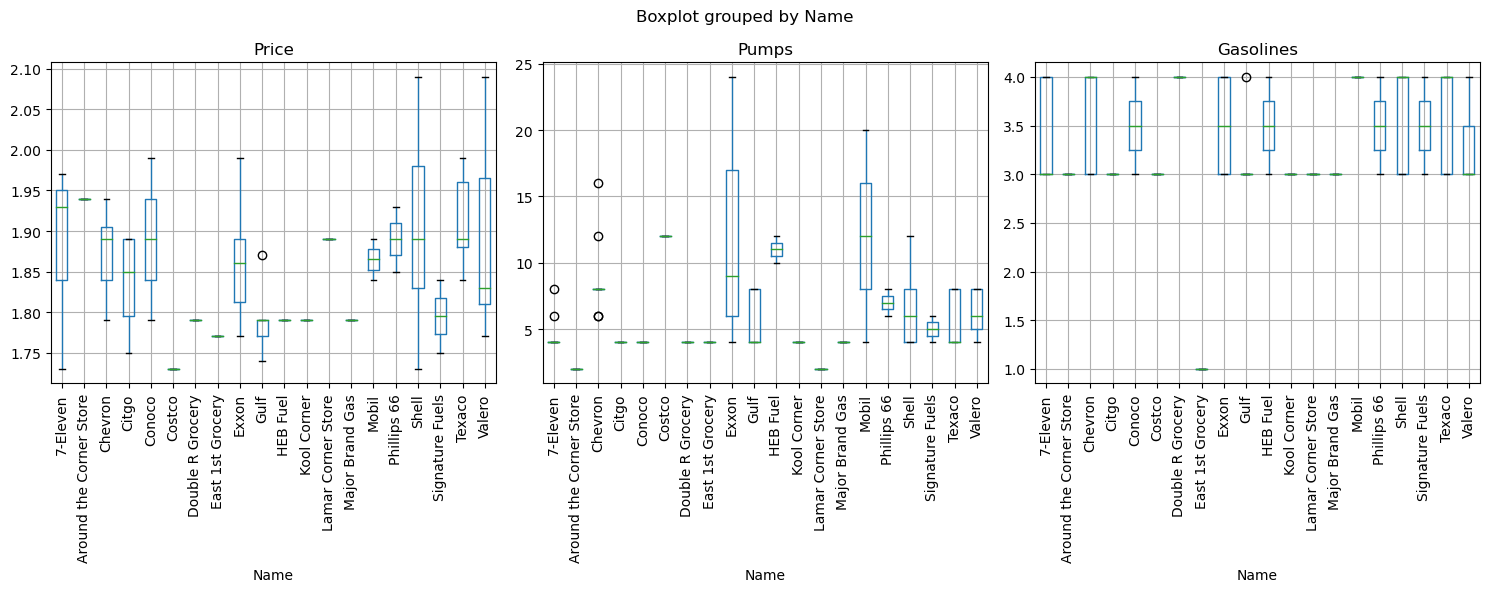

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(15, 6))

df.boxplot(column='Price', by='Name', ax=axes[0])
df.boxplot(column='Pumps', by='Name', ax=axes[1])
df.boxplot(column='Gasolines', by='Name', ax=axes[2])
for ax in axes:
    ax.tick_params(axis='x', rotation=90)

plt.tight_layout()
plt.show()


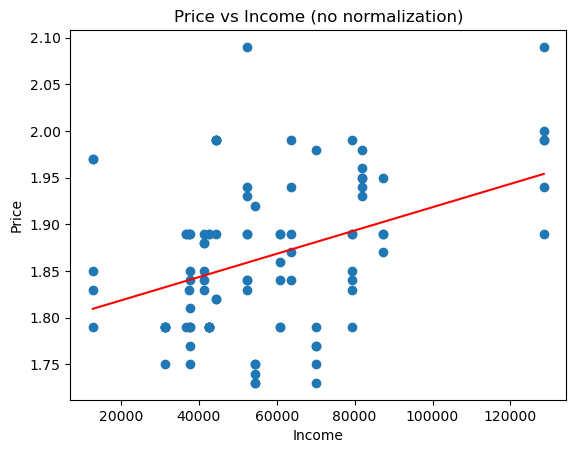

In [7]:
x = df['Income']
y = df['Price']

# 1. fit a line: np.polyfit returns [slope, intercept]
coeffs = np.polyfit(x, y, 1)

# 2. create the line function
line = np.poly1d(coeffs)

# 3. scatter plot
plt.scatter(x, y)

# 4. plot the line on top (generate x values, compute line(x))
x_line = np.linspace(x.min(), x.max(), 100)
plt.plot(x_line, line(x_line), color='red')

plt.xlabel('Income')
plt.ylabel('Price')
plt.title('Price vs Income (no normalization)')
plt.show()


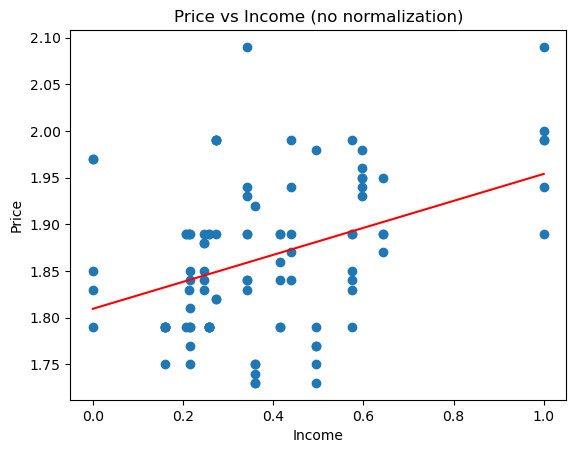

In [ ]:
def normalize(x):
    return (x - x.min()) / (x.max() - x.min())

x_normalized = normalize(df['Income'])
x = x_normalized
y = df['Price']

# 1. fit a line: np.polyfit returns [slope, intercept]
coeffs = np.polyfit(x, y, 1)

# 2. create the line function
line = np.poly1d(coeffs)

# 3. scatter plot
plt.scatter(x, y)

# 4. plot the line on top (generate x values, compute line(x))
x_line = np.linspace(x.min(), x.max(), 100)
plt.plot(x_line, line(x_line), color='red')

plt.xlabel('Income')
plt.ylabel('Price')
plt.title('Price vs Income (withnormalization)')
plt.show()


Normalization rescales the x-axis to [0,1] but does not change the underlying relationship between Income and Price. The trend and the fitted line remain the same.

In [12]:
# Select features and target
X = df[['Income', 'Pumps', 'Gasolines']].values
y = df['Price'].values
# Add bias column (column of ones)
ones = np.ones((X.shape[0], 1))
X = np.hstack([ones, X])
X.shape



(101, 4)

In [ ]:
np.random.seed(42) 
indices = np.arange(X.shape[0])
np.random.shuffle(indices)
split = int(0.8 * X.shape[0])
train_idx = indices[:split]
test_idx = indices[split:]
X_train, X_test = X[train_idx], X[test_idx]
y_train, y_test = y[train_idx], y[test_idx]


(21, 4)

In [17]:
A = X_train.T @ X_train
b = X_train.T @ y_train
A.shape

(4, 4)

In [19]:
b.shape

(4,)

In [20]:
def gaussian_elimination(A, b):
    n = A.shape[0]
    
    # Step 1: build augmented matrix [A|b]
    M = np.hstack([A.astype(float), b.reshape(-1,1).astype(float)])
    
    # Step 2: Forward elimination
    for i in range(n):
        # for each row below i, eliminate the value in column i
        for j in range(i+1, n):
            factor = M[j,i] / M[i,i]
            M[j] = M[j] - factor * M[i]
    
    # Step 3: Back substitution
    beta = np.zeros(n)
    for i in range(n-1, -1, -1):
        beta[i] = (M[i, -1] - np.dot(M[i, i+1:n], beta[i+1:n])) / M[i,i]
    
    return beta

beta_gauss = gaussian_elimination(A, b)
print(beta_gauss)


[ 1.73956676e+00  1.22766436e-06 -2.94344765e-03  2.06398543e-02]


In [21]:
def forward_substitution(L, b):
    n = L.shape[0]
    y = np.zeros(n)
    for i in range(n):                              # goes 0,1,2,3
        y[i] = (b[i] - np.dot(L[i, :i], y[:i])) / L[i, i]
    return y
def back_substitution(L, b):
    n = L.shape[0]
    beta = np.zeros(n)
    for i in range(n-1, -1, -1):
        beta[i] = (b[i] - np.dot(L.T[i,i+1:],beta[i+1:])) / L[i, i]
    return beta

def cholesky_solve(A, b):
    L = np.linalg.cholesky(A)
    y = forward_substitution(L, b)
    beta = back_substitution(L, y)
    return beta

beta_cholesky = cholesky_solve(A, b)
print(beta_cholesky)



[ 1.73956676e+00  1.22766436e-06 -2.94344765e-03  2.06398543e-02]


In [23]:
def qr_solve(X, y):
    Q, R = np.linalg.qr(X)
    b_qr = Q.T @ y
    beta = back_substitution(R.T, b_qr)
    return beta

beta_qr = qr_solve(X_train, y_train)
print(beta_qr)


[ 1.73956676e+00  1.22766436e-06 -2.94344765e-03  2.06398543e-02]


In [24]:
y_pred_gauss    = X_test @ beta_gauss
y_pred_cholesky = X_test @ beta_cholesky
y_pred_qr       = X_test @ beta_qr


In [25]:
print(y_pred_gauss)


[1.86442328 1.88417701 1.88861599 1.91164796 1.84202945 1.80540945
 1.84431414 1.85073617 1.84038929 1.83476536 1.88119784 1.83254035
 1.82747144 1.87386304 1.91090179 1.85665216 1.87328934 1.86867971
 1.83009631 1.85221809 1.84431414]


In [26]:
res_gauss    = np.abs(y_test - y_pred_gauss)
res_cholesky = np.abs(y_test - y_pred_cholesky)
res_qr       = np.abs(y_test - y_pred_qr)

print("Avg residual Gauss:    ", np.mean(res_gauss))
print("Avg residual Cholesky: ", np.mean(res_cholesky))
print("Avg residual QR:       ", np.mean(res_qr))


Avg residual Gauss:     0.0650910820685603
Avg residual Cholesky:  0.06509108206856046
Avg residual QR:        0.06509108206856076


In [27]:
rmse_gauss    = np.sqrt(np.mean((y_test - y_pred_gauss)**2))
rmse_cholesky = np.sqrt(np.mean((y_test - y_pred_cholesky)**2))
rmse_qr       = np.sqrt(np.mean((y_test - y_pred_qr)**2))

print("RMSE Gauss:    ", rmse_gauss)
print("RMSE Cholesky: ", rmse_cholesky)
print("RMSE QR:       ", rmse_qr)


RMSE Gauss:     0.07824374510111526
RMSE Cholesky:  0.07824374510111534
RMSE QR:        0.07824374510111588


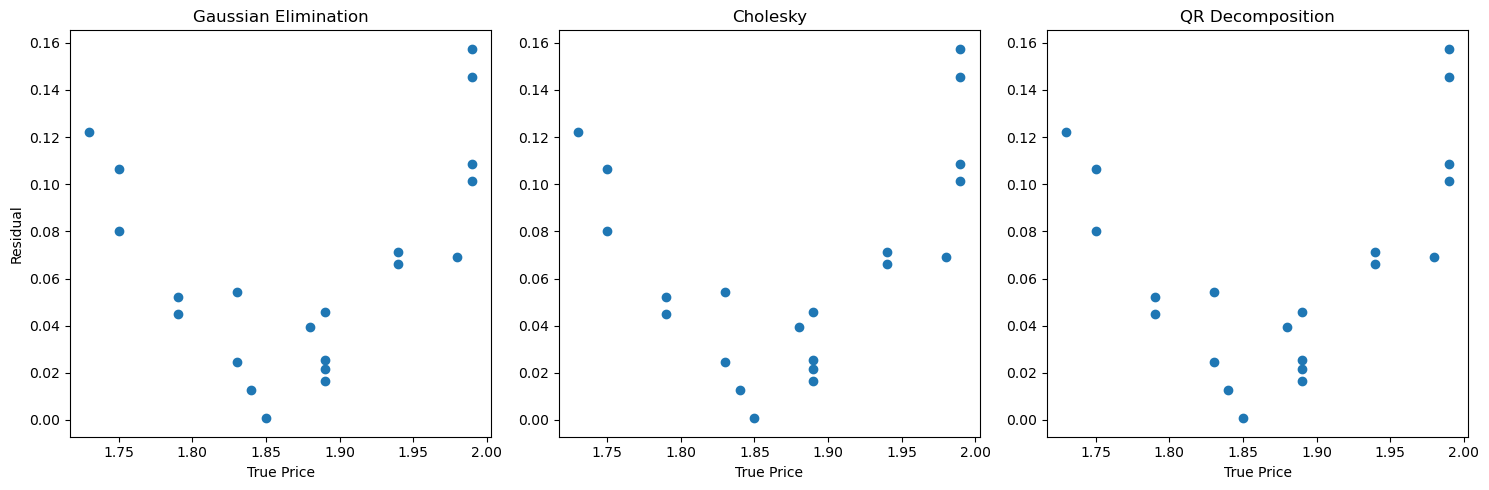

In [28]:
fig, axes = plt.subplots(1, 3, figsize=(15, 5))

axes[0].scatter(y_test, res_gauss)
axes[0].set_title('Gaussian Elimination')
axes[0].set_xlabel('True Price')
axes[0].set_ylabel('Residual')

axes[1].scatter(y_test, res_cholesky)
axes[1].set_title('Cholesky')
axes[1].set_xlabel('True Price')

axes[2].scatter(y_test, res_qr)
axes[2].set_title('QR Decomposition')
axes[2].set_xlabel('True Price')

plt.tight_layout()
plt.show()
